# M2 T2 Practical — K-means and DBSCAN

Revision: 11 September 2026

## Learning outcomes

- Fit and interpret K-means clusters and their arbitrary labels.
- Use inertia and silhouette critically alongside geometry.
- Identify DBSCAN core, border and noise observations.
- Investigate eps, min_samples and feature scaling with controlled comparisons.
- Recommend a clustering method using application requirements and limitations.

## How to work and submit

Plan for a two-hour session: about 90 minutes of core work and 30 minutes for discussion, debugging and checking. Timings beside questions are estimates, not deadlines. Setup and plotting support are supplied; focus on the modelling ideas.

Run cells in order. Replace `...` in TODO cells and write in each answer cell. Make a prediction **before** running an experiment; keep it even if the result surprises you, then explain the difference. If a cell fails, ask about the first error and retain your genuine attempt.

For every explanation, cite a number, observation or intermediate value from your own run, explain what it means, and justify your conclusion. Concise supported answers are enough. Different justified choices may be valid. Save your notebook with outputs and written answers. Supplied code alone is not a completed response.

The five core questions are assessed using the course's 50% completion/genuine attempt and 50% demonstrated understanding criteria. Optional extensions are not required. No new package installation or external dataset download is needed in the course Python environment (NumPy, pandas, matplotlib and scikit-learn).

## Preparation and links to the topic

Read [M2 T2 overview](https://learn.adelaide.edu.au/courses/30362/pages/module-2-topic-2-overview), K-means and DBSCAN in that topic, then [Evaluating Unsupervised Learning](https://learn.adelaide.edu.au/courses/30362/pages/evaluating-unsupervised-learning). Q1–2 connect fitting to inertia and silhouette; Q3 tests density rules and scaling; Q4–5 connect geometry to application decisions. The tutorial covers hand assignment/centroid updates; this practical tests larger-data interpretation. Silhouette/BIC derivations are not required.

These are synthetic observations with no verified customer labels. Any customer or service interpretation is an illustrative scenario.

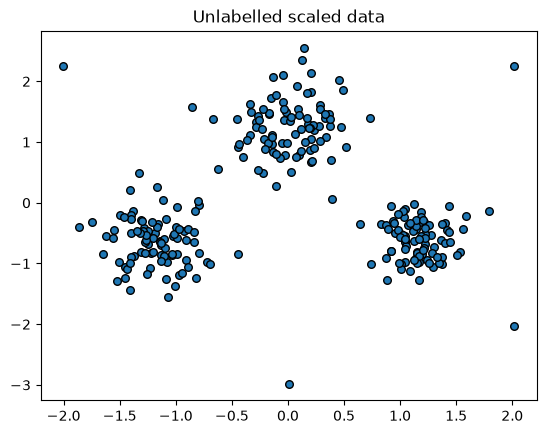

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
X_raw, _ = make_blobs(
    n_samples=260, centers=[(-4,-1), (0,3), (4,-1)],
    cluster_std=[0.8, 1.0, 0.7], random_state=12
)
X_raw = np.vstack([X_raw, [[-7,5], [7,5], [0,-6], [7,-4]]])
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

def show_clusters(labels, title, centers=None):
    plt.figure(figsize=(5.8, 3.8))
    plt.scatter(X[:,0], X[:,1], c=labels, cmap="tab10", edgecolor="k", s=30)
    if centers is not None:
        plt.scatter(centers[:,0], centers[:,1], c="black", marker="X", s=170)
    plt.title(title); plt.xlabel("Scaled feature 1"); plt.ylabel("Scaled feature 2"); plt.show()

plt.scatter(X[:,0], X[:,1], edgecolor="k", s=30)
plt.title("Unlabelled scaled data"); plt.show()

## Question 1 — Establish a baseline (10 minutes)

Complete `k`. We use `init="k-means++"` to choose spread-out starting centroids. `n_init=10` fits ten initialisations and retains the lowest-inertia result, reducing dependence on one unlucky start.

In your written answer, describe the fitted cluster shapes and sizes, explain what the centroids and numerical labels mean, and state what K-means does with the isolated observations.

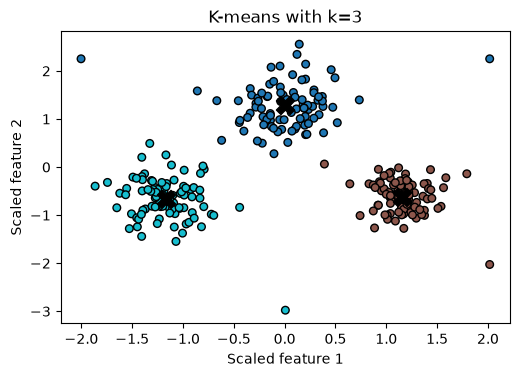

Inertia: 73.98
Cluster sizes: [88 88 88]


In [3]:
# TODO 1: use three clusters.
kmeans = KMeans(init="k-means++", n_clusters=3, n_init=10, random_state=RANDOM_STATE)
k_labels = kmeans.fit_predict(X)
show_clusters(k_labels, "K-means with k=3", kmeans.cluster_centers_)
print("Inertia:", round(kmeans.inertia_, 2))
print("Cluster sizes:", np.bincount(k_labels))

### Write your answer — Question 1

K-means with k=3 separates the data into three roughly equal circular clusters (each of size 88/88/88 points), with an inertia of 73.98. Inertia represents how the points are packed cohesively around a particular cluster. Centroids are marked by the black 'x' and it's placed at the center of each cluster, which represents the mean position of all points currently assigned to that cluster. 

Numerical labels (0,1,2) are arbitrary identifiers K-means assigns to points that indicate which cluster each point was placed in. They have no inherent meaning, rerunning K-means with a different seed could assign the same geometric cluster a different label entirely, so labels shouldn't be used for comparison across different runs. 

K-means doesn't have the ability to recognize whether a point is an outlier. We can see that there are 4 points that sits outside of the three clusters, but K-means still forces each one into whichever centroid is the least far away from that point, which is why they are still colored in. These outliers can quietly drag the cluster's centroid toward the outlier, even though the outlier doesn't represent that group at all.

## Question 2 — Choose k and test the evidence (15 minutes)

Compare k=2 through 6 using the supplied runner. Choose a defensible k and cite one inertia comparison and one silhouette comparison. Explain why declining inertia alone cannot select k. State one further check needed before treating these as customer segments.

,k,inertia,silhouette
0,2,288.734597,0.502297
1,3,73.978834,0.713734
2,4,62.580869,0.580183
3,5,52.072389,0.488229
4,6,46.272818,0.374035


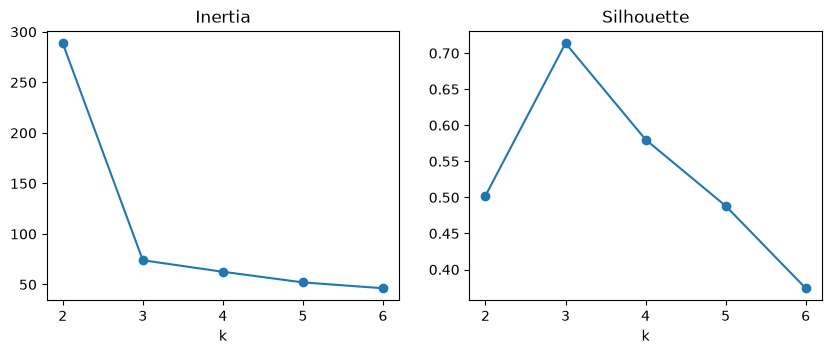

In [4]:
rows = []
# TODO 2: use k values 2, 3, 4, 5 and 6. Remember range stops before its second argument.
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    rows.append((k, model.inertia_, silhouette_score(X, labels)))
scores = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"])
display(scores)
fig, ax = plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(scores.k, scores.inertia, marker="o"); ax[0].set_title("Inertia")
ax[1].plot(scores.k, scores.silhouette, marker="o"); ax[1].set_title("Silhouette")
for a in ax: a.set_xlabel("k")
plt.show()

### Write your answer — Question 2

Across k=2 to 6, inertia decreases from 288.73 to 46.27, while silhouette rises from 0.502 (k=2) to a peak of 0.714 (k=3), then declines through 0.580, 0.488, down to 0.374 (k=6).

A defensible choice is k=3. It's somewhat low inertia (73.98) and high silhouette (0.714) are both reasonably compact and clearly separated, which balances the two criteria.

Inertia alone cannot select k because adding centroids gives the model more freedom and tends to reduce inertia. However, lower inertia, and therefore more clusters, doesn't guarantee that the clusters are meaningful. Silhouette can correct for this because it measures both the cohesion of the cluster and separation with other clusters. k=6 illustrates this, it has the lowest inertia (46.27) but the lowest silhouette (0.374), meaning its clusters are tightly packed internally but poorly separated from other clusters which would be confusing for us to interpret.

Before treating these as real customer segments, a check of stability across random seeds/initializations can be done. Since K-means depends on the initial centroid placement, a segmentation should only be trusted if rerunning with different seeds produces consistent cluster groupings.

Repeat initializations or resample records and compare which pairs remain together, rather than comparing raw label numbers. Ask domain experts whether the selected features and group summaries support a useful service decision. This dataset is synthetic: calling these customer regments is an illustrative application, not an established interpretation.

## Question 3 — Density and a controlled intervention (20 minutes)

Complete the masks and eps candidates below. Before running, predict how increasing eps changes core/noise counts. Compare the observed counts with your prediction. Then hold eps=0.32 fixed and compare min_samples=3 and 12 using dbscan_summary. Explain core, border and noise using the results, and why noise is not proof of an erroneous record. Finally predict what happens if feature 1 is measured in units 100 times larger without rescaling; run the supplied comparison and explain it.

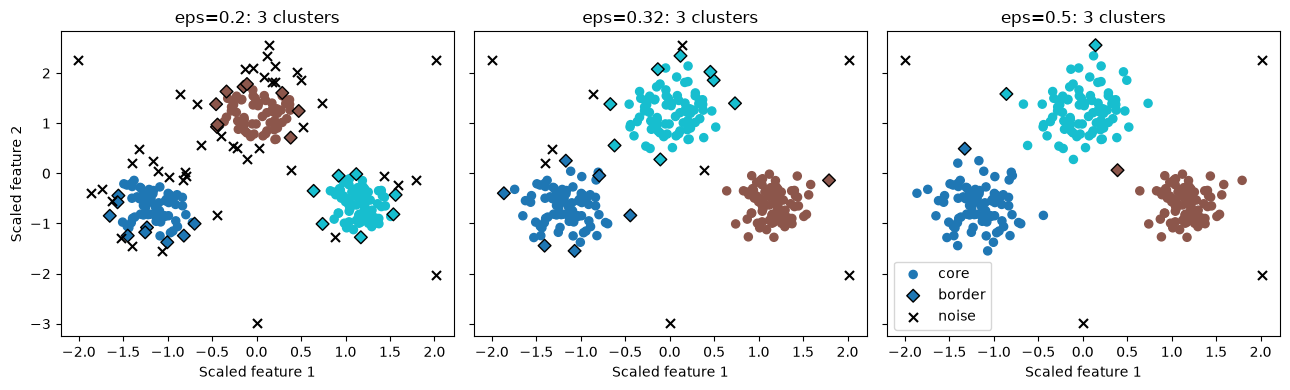

,eps,clusters,core,border,noise
0,0.20,3,195,25,44
1,0.32,3,240,15,9
2,0.50,3,256,4,4


3 3 254 5 5
12 3 199 43 22
original scaled clusters 3 noise 9
changed units, unscaled clusters 1 noise 258
changed units, rescaled clusters 3 noise 9


In [5]:
def dbscan_summary(eps, min_samples=5):
    model = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
    labels = model.labels_

    # TODO 3: create Boolean masks for core, noise and border points.
    core_mask = np.zeros(len(X), dtype=bool)
    core_mask[model.core_sample_indices_] = True
    noise_mask = (labels == -1)
    border_mask = (~core_mask & ~noise_mask)

    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    return labels, core_mask, border_mask, noise_mask, clusters

dbscan_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
# TODO 4: compare eps values 0.20, 0.32 and 0.50.
for axis, eps in zip(axes, [0.20, 0.32, 0.50]):
    labels, core, border, noise, clusters = dbscan_summary(eps)
    dbscan_rows.append({
        "eps": eps, "clusters": clusters,
        "core": int(core.sum()), "border": int(border.sum()),
        "noise": int(noise.sum()),
    })
    axis.scatter(X[core, 0], X[core, 1], c=labels[core], cmap="tab10", vmin=0, vmax=max(1, clusters-1), s=34, label="core")
    axis.scatter(X[border, 0], X[border, 1], c=labels[border], cmap="tab10", vmin=0, vmax=max(1, clusters-1), marker="D", s=42, edgecolor="black", label="border")
    axis.scatter(X[noise, 0], X[noise, 1], c="black", marker="x", s=42, label="noise")
    axis.set_title(f"eps={eps}: {clusters} clusters")
    axis.set_xlabel("Scaled feature 1")
axes[0].set_ylabel("Scaled feature 2")
axes[-1].legend(loc="best")
plt.tight_layout()
plt.show()
display(pd.DataFrame(dbscan_rows))


# TODO: change only min_samples in these two calls.
for minimum in [3, 12]:
    labels, core, border, noise, count = dbscan_summary(0.32, min_samples=minimum)
    print(minimum, count, int(core.sum()), int(border.sum()), int(noise.sum()))

# Supplied unit-change experiment: fixed eps/min_samples, no new fit choices.
X_units = X.copy(); X_units[:, 0] *= 100
for label, features in [("original scaled", X), ("changed units, unscaled", X_units), ("changed units, rescaled", StandardScaler().fit_transform(X_units))]:
    labs = DBSCAN(eps=0.32, min_samples=5).fit_predict(features)
    print(label, "clusters", len(set(labs)-{-1}), "noise", int((labs == -1).sum()))

### Write your answer — Question 3

Prediction: increasing eps increases the neighborhood radius, so more points can qualify as core points and fewer points are left as noise.

Actual: as eps rises from 0.2 to 0.5, core count rises from 195 to 256, and noise falls from 44 to 4, which confirms my prediction. Previous noise points gained enough nearby neighboors to either become border or core points as the radius widens. 

min_samples=3 vs 12 shows that raising min_samples causes the core count to drop from 254 to 199, border to rise from 5 to 43, and noise from 5 to 22. Raising min_samples raises the requirement for a point to become a core.

A core point has at least min_samples neighbors within its eps neighbourhood, so it is part of a dense region. A border point doesn't have enough neighbours to be a core point itself, but it is close enough to be a core point to be included in that cluster. A noise point is neither a core or a border point because it is not close enough to a dense region. Therefore, increasing min_samples can cause some points to mvoe from a core to border or from border to noise.

A high number of noise points doesn't necessarily mean the data is bad, it can simply be caused by the DBSCAN hyperparameter selection. For example, eps=0.2 produces 44 noise points, while increasing eps to 0.5 reduces this to only 4, even though the dataset itself has not changed. Similarly, increasing min_samples from 3 to 12 increases the noise from 5 to 22 because the requirement for bieng considered part of a dense region has become stricted.

If one feature has a much larger numerical value than another, it can dominate the distance calculation. Multiplying feature 1 by 100 without rescaling causes the number of clusters to fall from 3 to 1 and the number of noise points to increase from 9 to 258. This happens because the differences in feature 1 become much larger than the differences in feature 2, so the distances no longer represent the original relationship between the points. After using StandardScaler to rescale the features, the original result of 3 clusters and 9 noise points is restored. This shows that scaling can have major effect on DBSCAN's results.

In [6]:
X_moons_raw, _ = make_moons(n_samples=320, noise=0.08, random_state=RANDOM_STATE)
X_moons = StandardScaler().fit_transform(X_moons_raw)
def clustering_evidence(features, labels):
    keep = labels != -1
    groups = len(set(labels[keep]))
    # Silhouette requires 2 <= number of labels < number of scored observations.
    score = silhouette_score(features[keep], labels[keep]) if 2 <= groups < int(keep.sum()) else np.nan
    return groups, int((~keep).sum()), score
def compare_moons(eps_values):
    rows=[]; fig, axes=plt.subplots(1, len(eps_values)+1, figsize=(14,3.5))
    models=[('K-means', KMeans(n_clusters=2,n_init=10,random_state=42))]+[(f'DBSCAN eps={e}', DBSCAN(eps=e,min_samples=5)) for e in eps_values]
    for ax,(name,model) in zip(axes,models):
        labels=model.fit_predict(X_moons)
        groups,noise,score=clustering_evidence(X_moons,labels)
        rows.append((name,groups,noise,score))
        keep = labels != -1
        ax.scatter(X_moons[keep,0],X_moons[keep,1],c=labels[keep],cmap='tab10',s=12)
        if (~keep).any():
            ax.scatter(X_moons[~keep,0],X_moons[~keep,1],c='black',marker='x',s=18,label='noise')
            ax.legend(loc='best')
        ax.set_title(name); ax.set_xlabel('Scaled feature 1')
    axes[0].set_ylabel('Scaled feature 2');plt.tight_layout();plt.show()
    return pd.DataFrame(rows,columns=['method','clusters','noise','silhouette_non_noise'])

## Question 4 — Investigate curved groups (25 minutes)

The application defines each connected curved band as a useful group and permits some observations to remain unassigned. Before fitting, predict which algorithm assumptions suit this requirement. Complete a comparison of eps=0.15, 0.28 and 0.60; recommend one result using geometry, cluster/noise counts and silhouette. Explain any disagreement between the score and your recommendation. A missing silhouette is a valid outcome: explain why it is unavailable. When noise differs, note that scores describe different subsets.

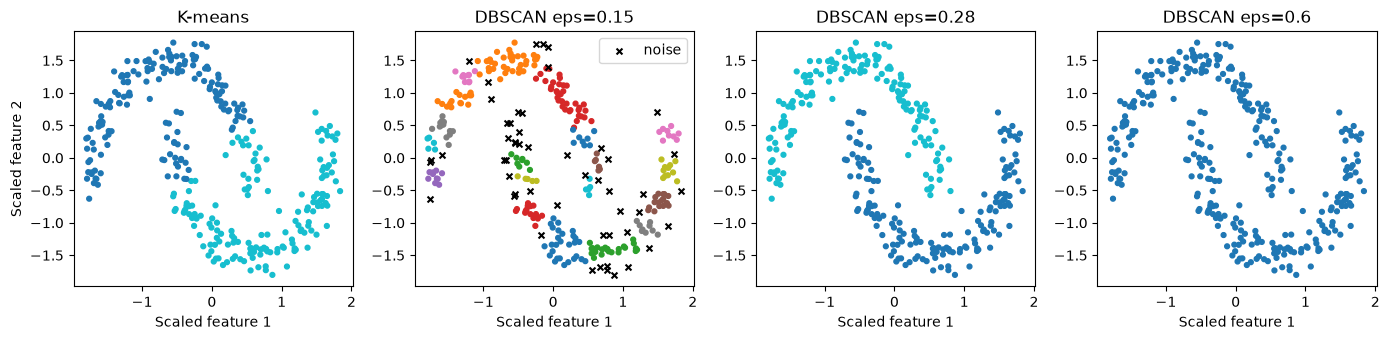

,method,clusters,noise,silhouette_non_noise
0,K-means,2,0,0.494406
1,DBSCAN eps=0.15,19,52,0.483456
2,DBSCAN eps=0.28,2,0,0.379331
3,DBSCAN eps=0.6,1,0,NaN


In [7]:
# TODO: supply the three candidate eps values.
moon_results = compare_moons([0.15, 0.28, 0.60])
display(moon_results)

### Write your answer — Question 4

Prediction: DBSCAN suits this task better than K-means because K-means assumes clusters are roughly convex/circular, while a curved band violates that assumption. DBSCAN instead looks for connected regions of nearby points, so that it can follow a curved shape even when the overall cluster is not compact.

With eps=0.15, DBSCAN uses a radius that is too small to connect the points along the moons. As a result, the moons are split into 19 small clusters, and 52 points are labelled as noise. With eps=0.6, the radius is tooo large, so the two clusters become connected and DBSCAN produces one big single cluster. The silhouette is mathematically undefined because there's no other cluster to collide with. Which means a missing score here is a valid and expected outcome and not an error.

DBSCAN with eps=0.28 would be the best choice because it preserves the two connected curved bands with no noise. DBSCAN with eps=0.28 has a lower silhouette score (0.379) than K-means (0.494). This doesn't necessarily mean K-means is better. Silhouette tend to favour clusters that are compact and well separated around their centers. The moon-shaped clusters are curved, so points at oppossite ends of the same moon can be far apart even though they don't belong to the same connected cluster. Therefore for this particular task, the shape of the clusters and the fact that DBSCAN correctly identifies the two arcs are more important than the silhouette score alone.

## Question 5 — Make a defensible recommendation (20 minutes)

Two teams want to reuse your results. Team A needs exactly three compact service territories and must assign every record. Team B wants connected regions and can send unusual records for manual review. Recommend a method for each, using one result from this notebook. For Team B, propose a concrete check before deployment when a valid region has lower density. State how duplicated records could affect density-based clustering and what data checks you would perform. Do not describe fitted labels as real identities.

### Write your answer — Question 5

Team A would benefit more from using K-means because their dataset involves 'compact' service territories and 'must' assign every record. K-means determines dense points better because it calculates the distance of each of the point against the chosen centroids.

Team B would benefit more from using DBSCAN because their dataset contains 'connected' regions and can send 'unusual' records for manual review. DBSCAN determines connected points better because it uses radius to determine whether a certain area is densed enough to be clustered together.

Before using it with a sparse valid region: identify a domain-confirmed sample from that region, inspect its local neighbour counts and noise fraction, and compare nearby eps/min_samples settings. Check whether recovering that region merges other regions. A single global density rule may be unsuitable if no setting serves both dense and sparse regions.

Duplicate records affect DBSCAN because it counts the number of points in eps when deciding whether a point is a core point. If the same observation appears multiple times, DBSCAN can count these duplicates as separate neighbors. This can make an area appear denser than it really is and cause a point to become a core point when it otherwise would not. This could lead to incorrect clusters or cause separate clusters to be joined together. Therefore, duplicate records should be checked before applying DBSCAN.

## Optional extensions

Complete these only after the core. Each is worth up to 5 bonus marks under the course policy; omitting either loses no core marks.

- Repeat K-means across five seeds and report stability without comparing arbitrary label numbers directly.
- Repeat the moons comparison at a second noise level and assess whether your recommendation still holds.

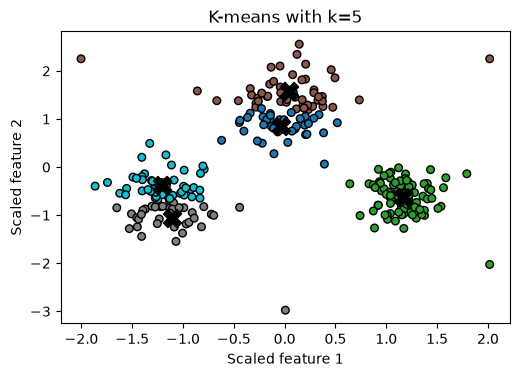

Inertia: 52.07
Cluster sizes: [38 87 51 37 51]


In [8]:
# K-Means repetition with k=5
kmeans = KMeans(init="k-means++", n_clusters=5, n_init=10, random_state=RANDOM_STATE)
k_labels = kmeans.fit_predict(X)
show_clusters(k_labels, "K-means with k=5", kmeans.cluster_centers_)
print("Inertia:", round(kmeans.inertia_, 2))
print("Cluster sizes:", np.bincount(k_labels))

### Extension 1 Answer
When K-means is run with k=5, the inertia is 52.07 and the cluster sizes are [38 87 51 37 51]. The clusters are therefore much less evenly sized compared with k=3. The plot shows that some of the clusters overlap, suggesting that increasing k doesn't necessarily produce better or more meaningful clusters. A lower inertia alone is therefore not enough to decide that k=5 is better.

To check whether K-means is stable, we should run it multiple times with different random starting points and compare the actual cluster membership rather than the cluster label numbers. The labels themselves are arbitrary, so cluster 2 in one run could represent the same group as cluster 0 in another run. For example, if two groups run exactly the same points together but give them different numbers, the clustering is still stable.

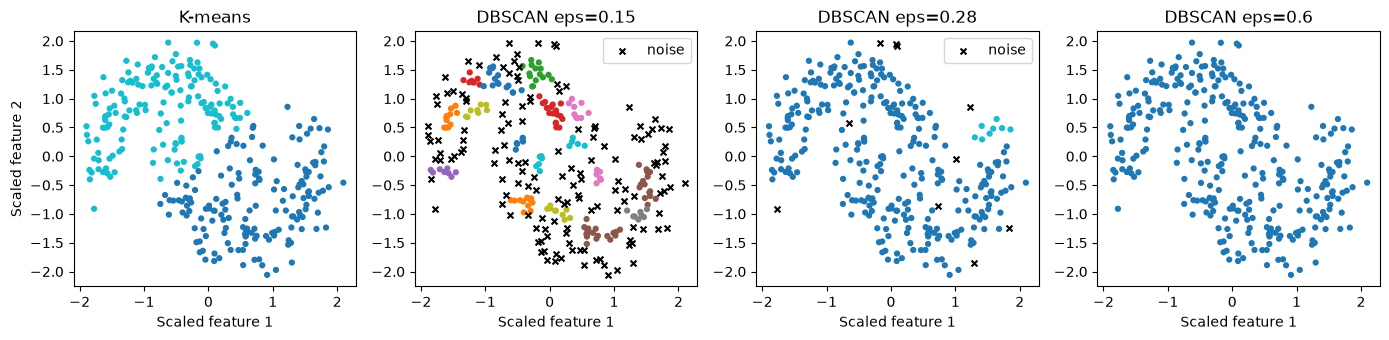

,method,clusters,noise,silhouette_non_noise
0,K-means,2,0,0.480195
1,DBSCAN eps=0.15,17,144,0.567104
2,DBSCAN eps=0.28,2,10,0.115690
3,DBSCAN eps=0.6,1,0,NaN


In [9]:
# Moon comparison at second noise level
X_moons_raw, _ = make_moons(n_samples=320, noise=0.16, random_state=RANDOM_STATE)
X_moons = StandardScaler().fit_transform(X_moons_raw)
def clustering_evidence(features, labels):
    keep = labels != -1
    groups = len(set(labels[keep]))
    score = silhouette_score(features[keep], labels[keep]) if 2 <= groups < int(keep.sum()) else np.nan
    return groups, int((~keep).sum()), score
def compare_moons(eps_values):
    rows=[]; fig, axes=plt.subplots(1, len(eps_values)+1, figsize=(14,3.5))
    models=[('K-means', KMeans(n_clusters=2,n_init=10,random_state=42))]+[(f'DBSCAN eps={e}', DBSCAN(eps=e,min_samples=5)) for e in eps_values]
    for ax,(name,model) in zip(axes,models):
        labels=model.fit_predict(X_moons)
        groups,noise,score=clustering_evidence(X_moons,labels)
        rows.append((name,groups,noise,score))
        keep = labels != -1
        ax.scatter(X_moons[keep,0],X_moons[keep,1],c=labels[keep],cmap='tab10',s=12)
        if (~keep).any():
            ax.scatter(X_moons[~keep,0],X_moons[~keep,1],c='black',marker='x',s=18,label='noise')
            ax.legend(loc='best')
        ax.set_title(name); ax.set_xlabel('Scaled feature 1')
    axes[0].set_ylabel('Scaled feature 2');plt.tight_layout();plt.show()
    return pd.DataFrame(rows,columns=['method','clusters','noise','silhouette_non_noise'])

moon_results = compare_moons([0.15, 0.28, 0.60])
display(moon_results)

### Extension 2 Answer
When the noise level is increased to 0.16, the previous eps=0.28 setting no longer works as well. DBSCAN now labels 10 points as noise and has a much lower silhouette score of 0.116, while K-means still assigns all points to a cluster and has a silhouette score of 0.48. 

This happens because the higher noise level makes the points more spread out from the original curves. The two arcs become less clearly separated, and there are larger gaps between points within each arc. As a result, some points that DBSCAN previously connected may no longer have enough nearby points within eps, causing them to be labelled as noise. At the same time, some points from the two arcs may be close enough to become incorrectly connected, This shows that DBSCAN is sensitive to the choice of eps, and a value that works well for one dataset may not work well when the amount of noise changes.